# cuDF-Polars filter analysis

This notebook measures only the native filter operation for CPU, CUDA, and Triton. Inputs, masks, backend conversions, and result validation are prepared outside the timed call.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import polars as pl
import torch
import pylibcudf as plc
from rmm.pylibrmm.stream import DEFAULT_STREAM

repo_root = Path.cwd().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd()
python_root = repo_root / 'python' / 'cudf_polars'
if str(python_root) not in sys.path:
    sys.path.insert(0, str(python_root))

from cudf_polars.analysis.operation_benchmark import time_cpu, time_cuda
from cudf_polars.containers import Column, DataFrame, DataType
from cudf_polars.triton.components.column_triton import TritonColumn
from cudf_polars.triton.triton_conversion import (
    column_cudf_to_triton,
    dataframe_cudf_to_triton,
)

In [2]:
cudf_stream = DEFAULT_STREAM
num_columns = 4
selectivity = 0.5
warmups = 3
repeats = 10

def benchmark(cases, warmups, repeats, name): 
    benchmark_rows = []
    for num_rows, case in cases.items():
        timings = {}
        if "cpu" in case:
            timings["cpu"] = time_cpu(
                case["cpu"], warmups=warmups, repeats=repeats
            )
        if "triton" in case:
            timings["triton"] = time_cuda(
                case["triton"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            )
        if "cuda" in case:
            timings["cuda"] = time_cuda(
                case["cuda"],
                stream=cudf_stream,
                warmups=warmups,
                repeats=repeats,
            )
        for backend, timing in timings.items():
            benchmark_rows.append(
                {
                    "operation": name,
                    "backend": backend,
                    "rows": num_rows,
                    "mean_ms": timing.mean_ms,
                    "median_ms": timing.median_ms,
                    "min_ms": timing.min_ms,
                }
            )
        print(f"completed {name} case: {num_rows:,} rows")

    results = pl.DataFrame(benchmark_rows)
    return results

def validate(cases):
    for num_rows, case in cases.items():
        results = {}
        if "cpu" in case:
            results["cpu"] = case["cpu"]()
        if "cuda" in case:
            results["cuda"] = case["cuda"]()
        if "triton" in case:
            results["triton"] = case["triton"]()
        cudf_stream.synchronize()

        expected_rows = case["expected_rows"]
        if "cpu" in results:
            assert results["cpu"].height == expected_rows
        if "cuda" in results:
            assert results["cuda"].num_rows == expected_rows
        if "triton" in results:
            assert results["triton"].num_rows == expected_rows
        print(f"validated filter output: {num_rows:,} rows -> {expected_rows:,} rows")

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def plot(results, title):
    plot_df = results.sort("rows")
    colors = {"triton": "C0", "cuda": "C1", "cpu": "C2"}

    for backend in plot_df["backend"].unique():
        data = plot_df.filter(pl.col("backend") == backend)

        plt.plot(
            data["rows"].to_list(),
            data["median_ms"].to_list(),
            marker="o",
            label=backend,
            color=colors.get(backend),
        )

    plt.xscale("log")
    plt.gca().xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )
    plt.xlabel("Rows")
    plt.ylabel("Median time (ms)")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Filter and sort benchmark

This benchmark measures two layers: filtering the input and sorting the retained rows by one key. Both operators run inside the timed callable for each backend.

In [4]:
from cudf_polars.triton.triton_operations.sort_triton import sort_indices

filter_sort_cases = {}
sort_sizes = (100_000, 300_000, 1_000_000, 3_000_000, 6_000_000, 10_000_000)
sort_order = [plc.types.Order.ASCENDING]
sort_null_order = [plc.types.NullOrder.BEFORE]

for num_rows in sort_sizes:
    rng = np.random.default_rng(42)
    values = rng.permutation(num_rows).astype(np.int64)
    mask_values = (np.arange(num_rows) % 2) == 0
    cpu_frame = pl.DataFrame({"key": values, "value": values.astype(np.float32)})
    cpu_mask = pl.Series("mask", mask_values)

    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name="mask",
    )
    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(cudf_mask, name="mask", stream=cudf_stream)

    def cpu_filter_sort(frame=cpu_frame, mask=cpu_mask):
        return frame.filter(mask).sort("key")

    def cuda_filter_sort(frame=cudf_frame, mask=cudf_mask):
        filtered = frame.filter(mask)
        return plc.sorting.stable_sort_by_key(
            filtered.table,
            plc.Table([filtered.column_map["key"].obj]),
            sort_order,
            sort_null_order,
            stream=cudf_stream,
        )

    def triton_filter_sort(frame=triton_frame, mask=triton_mask):
        filtered = frame.filter(mask)
        return sort_indices(
            [filtered.column_map["key"]],
            sort_order,
            sort_null_order,
            torch.cuda.current_stream(),
        )

    expected_rows = int(mask_values.sum())
    filter_sort_cases[num_rows] = {
        "cpu": cpu_filter_sort,
        "cuda": cuda_filter_sort,
        "triton": triton_filter_sort,
        "expected_rows": expected_rows,
    }

filter_sort_results = benchmark(
    filter_sort_cases, warmups=warmups, repeats=repeats, name="filter + sort"
)
filter_sort_results

completed filter + sort case: 100,000 rows
completed filter + sort case: 300,000 rows
completed filter + sort case: 1,000,000 rows
completed filter + sort case: 3,000,000 rows
completed filter + sort case: 6,000,000 rows
completed filter + sort case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter + sort""","""cpu""",100000,2.3042206,2.777346,1.223235
"""filter + sort""","""cuda""",100000,1.292499,1.207216,1.13152
"""filter + sort""","""triton""",100000,1.031139,0.965216,0.892928
"""filter + sort""","""cpu""",300000,2.0933149,2.039249,1.765333
"""filter + sort""","""cuda""",300000,2.809773,2.686848,2.44144
…,…,…,…,…,…
"""filter + sort""","""cuda""",6000000,10.317811,10.331968,10.015744
"""filter + sort""","""triton""",6000000,9.696826,9.606768,9.335808
"""filter + sort""","""cpu""",10000000,80.69185,79.950412,77.344409


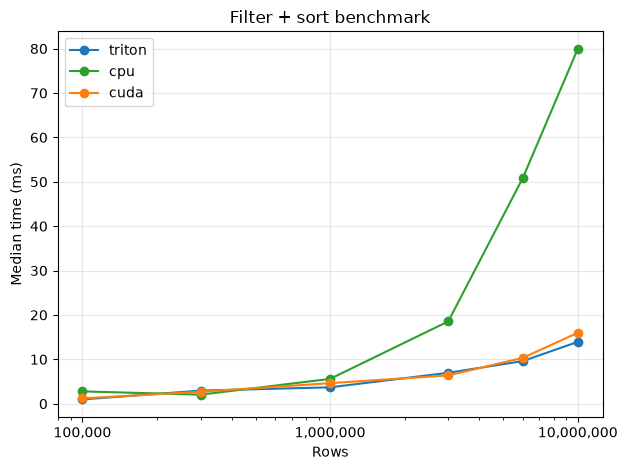

In [5]:
# for num_rows, case in filter_sort_cases.items():
#     cpu_result = case["cpu"]()
#     cuda_result = case["cuda"]()
#     triton_result = case["triton"]()
#     cudf_stream.synchronize()
#     assert cpu_result.height == case["expected_rows"]
#     assert cuda_result.num_rows() == case["expected_rows"]
#     assert triton_result.numel() == case["expected_rows"]

plot(filter_sort_results, "Filter + sort benchmark")

completed filter + sort case: 100,000 rows
completed filter + sort case: 300,000 rows
completed filter + sort case: 1,000,000 rows
completed filter + sort case: 3,000,000 rows
completed filter + sort case: 6,000,000 rows
completed filter + sort case: 10,000,000 rows
completed filter + sort case: 30,000,000 rows
shape: (14, 6)
┌───────────────┬─────────┬──────────┬───────────┬───────────┬───────────┐
│ operation     ┆ backend ┆ rows     ┆ mean_ms   ┆ median_ms ┆ min_ms    │
│ ---           ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---       │
│ str           ┆ str     ┆ i64      ┆ f64       ┆ f64       ┆ f64       │
╞═══════════════╪═════════╪══════════╪═══════════╪═══════════╪═══════════╡
│ filter + sort ┆ cuda    ┆ 100000   ┆ 1.550893  ┆ 1.54088   ┆ 1.11616   │
│ filter + sort ┆ triton  ┆ 100000   ┆ 0.990966  ┆ 0.985008  ┆ 0.907232  │
│ filter + sort ┆ cuda    ┆ 300000   ┆ 2.54888   ┆ 2.513456  ┆ 2.388992  │
│ filter + sort ┆ triton  ┆ 300000   ┆ 3.41721   ┆ 3.552256  ┆ 2.366464 

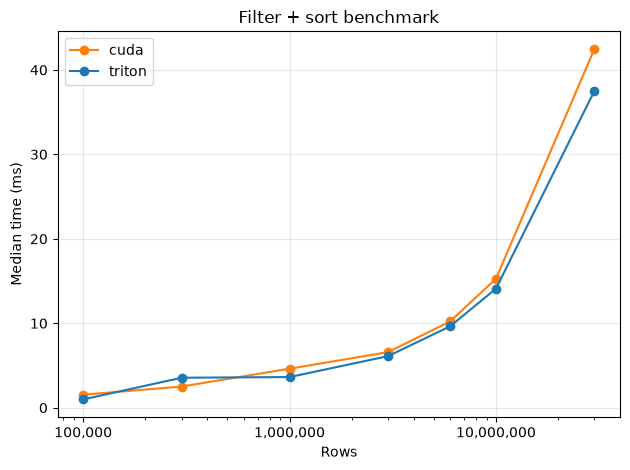

In [4]:
from cudf_polars.triton.triton_operations.sort_triton import sort_indices

filter_sort_cases = {}
sort_sizes = (100_000, 300_000, 1_000_000, 3_000_000, 6_000_000, 10_000_000, 30_000_000)
sort_order = [plc.types.Order.ASCENDING]
sort_null_order = [plc.types.NullOrder.BEFORE]

for num_rows in sort_sizes:
    rng = np.random.default_rng(42)
    values = rng.permutation(num_rows).astype(np.int64)
    mask_values = (np.arange(num_rows) % 2) == 0
    cpu_frame = pl.DataFrame({"key": values, "value": values.astype(np.float32)})
    cpu_mask = pl.Series("mask", mask_values)

    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name="mask",
    )
    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(cudf_mask, name="mask", stream=cudf_stream)

    def cpu_filter_sort(frame=cpu_frame, mask=cpu_mask):
        return frame.filter(mask).sort("key")

    def cuda_filter_sort(frame=cudf_frame, mask=cudf_mask):
        filtered = frame.filter(mask)
        return plc.sorting.stable_sort_by_key(
            filtered.table,
            plc.Table([filtered.column_map["key"].obj]),
            sort_order,
            sort_null_order,
            stream=cudf_stream,
        )

    def triton_filter_sort(frame=triton_frame, mask=triton_mask):
        filtered = frame.filter(mask)
        return sort_indices(
            [filtered.column_map["key"]],
            sort_order,
            sort_null_order,
            torch.cuda.current_stream(),
        )

    expected_rows = int(mask_values.sum())
    filter_sort_cases[num_rows] = {
        # "cpu": cpu_filter_sort,
        "cuda": cuda_filter_sort,
        "triton": triton_filter_sort,
        "expected_rows": expected_rows,
    }

filter_sort_results = benchmark(
    filter_sort_cases, warmups=warmups, repeats=repeats, name="filter + sort"
)

plot(filter_sort_results, "Filter + sort benchmark")

## Filter and distinct benchmark

This benchmark measures two layers: filtering the input and removing duplicate keys from the retained rows. The complete pipeline is timed for each backend.

In [ ]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices


filter_distinct_cases = {}
distinct_sizes = (100_000, 300_000, 1_000_000, 3_000_000, 6_000_000, 10_000_000)
distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST

for num_rows in distinct_sizes:
    num_unique = max(1, num_rows // 10)
    values = np.arange(num_rows, dtype=np.int64) % num_unique
    mask_values = (np.arange(num_rows) % 3) != 0
    cpu_frame = pl.DataFrame({"key": values})
    cpu_mask = pl.Series("mask", mask_values)

    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)
    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name="mask",
    )
    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(cudf_mask, name="mask", stream=cudf_stream)

    def cpu_filter_distinct(frame=cpu_frame, mask=cpu_mask):
        return frame.filter(mask).unique(maintain_order=False)

    def cuda_filter_distinct(frame=cudf_frame, mask=cudf_mask):
        filtered = frame.filter(mask)
        return plc.stream_compaction.stable_distinct(
            plc.Table([filtered.column_map["key"].obj]),
            [0],
            distinct_keep,
            plc.types.NullEquality.EQUAL,
            plc.types.NanEquality.ALL_EQUAL,
            stream=cudf_stream,
        )

    def triton_filter_distinct(frame=triton_frame, mask=triton_mask):
        filtered = frame.filter(mask)
        key = filtered.column_map["key"]
        return distinct_triton_indices(
            [key], torch.argsort(key.obj, stable=True), distinct_keep
        )

    expected_rows = int(np.unique(values[mask_values]).size)
    filter_distinct_cases[num_rows] = {
        "cpu": cpu_filter_distinct,
        "cuda": cuda_filter_distinct,
        "triton": triton_filter_distinct,
        "expected_rows": expected_rows,
    }

filter_distinct_results = benchmark(
    filter_distinct_cases,
    warmups=warmups,
    repeats=repeats,
    name="filter + distinct",
)
filter_distinct_results

completed filter + distinct case: 100,000 rows
completed filter + distinct case: 300,000 rows
completed filter + distinct case: 1,000,000 rows
completed filter + distinct case: 3,000,000 rows
completed filter + distinct case: 6,000,000 rows
completed filter + distinct case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter + distinct""","""cpu""",100000,1.2041999,1.2113515,1.097134
"""filter + distinct""","""cuda""",100000,1.256186,1.172864,0.969728
"""filter + distinct""","""triton""",100000,1.801261,1.662544,1.555616
"""filter + distinct""","""cpu""",300000,1.6051246,1.6036565,1.476515
"""filter + distinct""","""cuda""",300000,2.410848,2.349152,2.198528
…,…,…,…,…,…
"""filter + distinct""","""cuda""",6000000,9.212067,9.213584,8.913856
"""filter + distinct""","""triton""",6000000,12.795398,10.308592,10.118144
"""filter + distinct""","""cpu""",10000000,88.173564,88.251155,82.553936


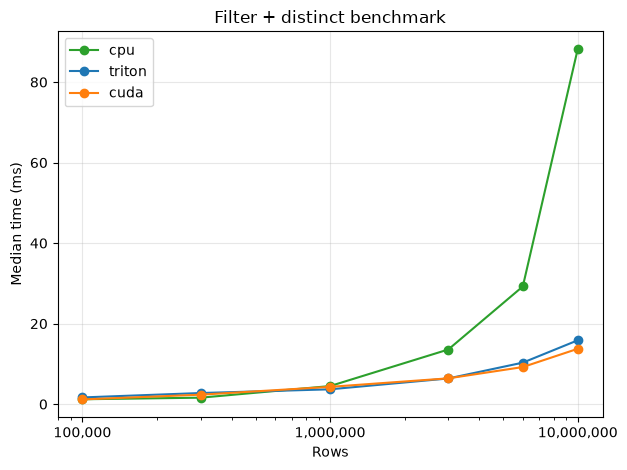

In [ ]:
for num_rows, case in filter_distinct_cases.items():
    # cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    # assert cpu_result.height == case["expected_rows"]
    assert cuda_result.num_rows() == case["expected_rows"]
    assert triton_result.numel() == case["expected_rows"]

plot(filter_distinct_results, "Filter + distinct benchmark")

## Join and distinct benchmark

This benchmark measures an inner join followed by distinct key selection. The join and distinct operations are both included in the timed callable for each backend; inputs and result validation remain outside the timed region.

In [7]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices
from cudf_polars.analysis.operation_benchmark import generate_join_data
from cudf_polars.triton.triton_operations.join_triton import join_pairs

join_distinct_cases = {}
join_distinct_sizes = (100_000, 300_000, 1_000_000, 3_000_000, 10_000_000)
join_distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST

for num_rows in join_distinct_sizes:
    join_data = generate_join_data(num_rows, num_columns=1)
    left_frame = DataFrame.from_polars(join_data.left, stream=cudf_stream)
    right_frame = DataFrame.from_polars(join_data.right, stream=cudf_stream)
    left_key = column_cudf_to_triton(left_frame.column_map[join_data.key], name=join_data.key, stream=cudf_stream)
    right_key = column_cudf_to_triton(right_frame.column_map[join_data.key], name=join_data.key, stream=cudf_stream)
    triton_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    key = join_data.key
    right_size = join_data.right.height

    def cpu_join_distinct(left=join_data.left, right=join_data.right, key=key):
        return left.join(right, on=key, how="inner").unique(subset=key, maintain_order=False)

    def cuda_join_distinct(left=left_frame, right=right_frame, key=key):
        left_map, _ = plc.join.inner_join(plc.Table([left.column_map[key].obj]), plc.Table([right.column_map[key].obj]), plc.types.NullEquality.EQUAL, stream=cudf_stream)
        (joined_key,) = plc.copying.gather(plc.Table([left.column_map[key].obj]), left_map, plc.copying.OutOfBoundsPolicy.DONT_CHECK, stream=cudf_stream).columns()
        return plc.stream_compaction.stable_distinct(plc.Table([joined_key]), [0], join_distinct_keep, plc.types.NullEquality.EQUAL, plc.types.NanEquality.ALL_EQUAL, stream=cudf_stream)

    def triton_join_distinct(left=left_key, right=right_key, n_left=num_rows, n_right=right_size):
        left_indices, _ = join_pairs([left], [right], "Inner", True, device=triton_device, n_left=n_left, n_right=n_right)
        joined_key = TritonColumn(left.obj[left_indices], dtype=left.dtype)
        sorted_indices = torch.argsort(joined_key.obj, stable=True)
        return distinct_triton_indices([joined_key], sorted_indices, join_distinct_keep)

    join_distinct_cases[num_rows] = {
        "cpu": cpu_join_distinct,
        "cuda": cuda_join_distinct,
        "triton": triton_join_distinct,
        "expected_rows": right_size,
    }


In [8]:
join_distinct_results = benchmark(
    join_distinct_cases,
    warmups=warmups,
    repeats=repeats,
    name="join + distinct",
)
join_distinct_results

completed join + distinct case: 100,000 rows
completed join + distinct case: 300,000 rows
completed join + distinct case: 1,000,000 rows
completed join + distinct case: 3,000,000 rows
completed join + distinct case: 10,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""join + distinct""","""cpu""",100000,4.1566899,4.156673,3.758132
"""join + distinct""","""cuda""",100000,4.461568,4.269568,2.646016
"""join + distinct""","""triton""",100000,4.849357,4.077568,3.801088
"""join + distinct""","""cpu""",300000,5.8836877,5.6423705,4.781977
"""join + distinct""","""cuda""",300000,13.765222,13.528064,9.394176
…,…,…,…,…,…
"""join + distinct""","""cuda""",3000000,15.071305,15.188896,14.162944
"""join + distinct""","""triton""",3000000,13.076346,13.259728,12.001152
"""join + distinct""","""cpu""",10000000,323.851593,328.155917,282.59509


validated join + distinct output: 100,000 left rows -> 25,000 keys
validated join + distinct output: 300,000 left rows -> 75,000 keys
validated join + distinct output: 1,000,000 left rows -> 250,000 keys
validated join + distinct output: 3,000,000 left rows -> 750,000 keys
validated join + distinct output: 10,000,000 left rows -> 2,500,000 keys


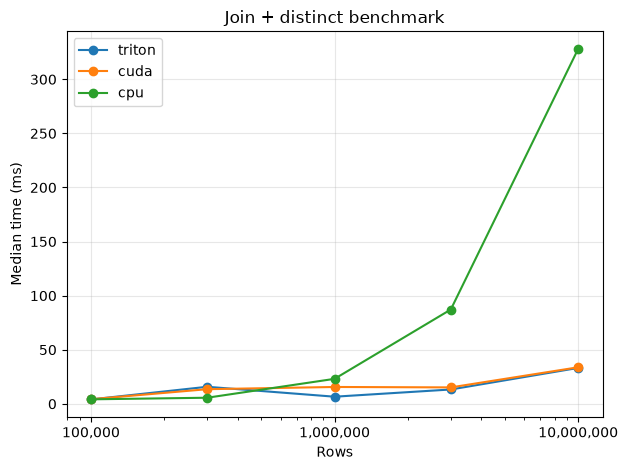

In [11]:
for num_rows, case in join_distinct_cases.items():
    cpu_result = case["cpu"]()
    (cuda_result,) = case["cuda"]().columns()
    triton_result = case["triton"]()
    cudf_stream.synchronize()

    expected_rows = case["expected_rows"]
    assert cpu_result.height == expected_rows
    assert cuda_result.size() == expected_rows
    assert triton_result.numel() == expected_rows
    print(f"validated join + distinct output: {num_rows:,} left rows -> {expected_rows:,} keys")

plot(join_distinct_results, "Join + distinct benchmark")

completed join + distinct case: 100,000 rows
completed join + distinct case: 300,000 rows
completed join + distinct case: 1,000,000 rows
completed join + distinct case: 3,000,000 rows
completed join + distinct case: 10,000,000 rows
completed join + distinct case: 30,000,000 rows
shape: (12, 6)
┌─────────────────┬─────────┬──────────┬───────────┬───────────┬───────────┐
│ operation       ┆ backend ┆ rows     ┆ mean_ms   ┆ median_ms ┆ min_ms    │
│ ---             ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---       │
│ str             ┆ str     ┆ i64      ┆ f64       ┆ f64       ┆ f64       │
╞═════════════════╪═════════╪══════════╪═══════════╪═══════════╪═══════════╡
│ join + distinct ┆ triton  ┆ 100000   ┆ 1.528102  ┆ 1.481696  ┆ 1.351296  │
│ join + distinct ┆ cuda    ┆ 100000   ┆ 1.278486  ┆ 1.150096  ┆ 1.048704  │
│ join + distinct ┆ triton  ┆ 300000   ┆ 4.248976  ┆ 4.215808  ┆ 3.95744   │
│ join + distinct ┆ cuda    ┆ 300000   ┆ 4.56577   ┆ 4.522432  ┆ 4.19632   │
│ join + dis

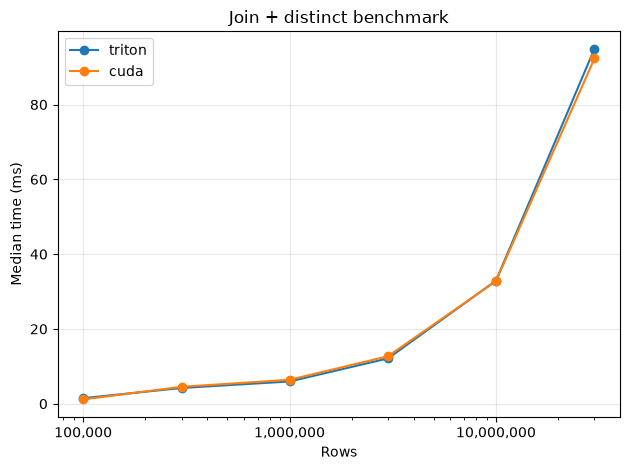

In [4]:
from cudf_polars.triton.triton_operations.distinct_triton import distinct_triton_indices
from cudf_polars.analysis.operation_benchmark import generate_join_data
from cudf_polars.triton.triton_operations.join_triton import join_pairs

join_distinct_cases = {}
join_distinct_sizes = (100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000)
join_distinct_keep = plc.stream_compaction.DuplicateKeepOption.KEEP_FIRST

for num_rows in join_distinct_sizes:
    join_data = generate_join_data(num_rows, num_columns=1)
    left_frame = DataFrame.from_polars(join_data.left, stream=cudf_stream)
    right_frame = DataFrame.from_polars(join_data.right, stream=cudf_stream)
    left_key = column_cudf_to_triton(left_frame.column_map[join_data.key], name=join_data.key, stream=cudf_stream)
    right_key = column_cudf_to_triton(right_frame.column_map[join_data.key], name=join_data.key, stream=cudf_stream)
    triton_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    key = join_data.key
    right_size = join_data.right.height

    def cpu_join_distinct(left=join_data.left, right=join_data.right, key=key):
        return left.join(right, on=key, how="inner").unique(subset=key, maintain_order=False)

    def cuda_join_distinct(left=left_frame, right=right_frame, key=key):
        left_map, _ = plc.join.inner_join(plc.Table([left.column_map[key].obj]), plc.Table([right.column_map[key].obj]), plc.types.NullEquality.EQUAL, stream=cudf_stream)
        (joined_key,) = plc.copying.gather(plc.Table([left.column_map[key].obj]), left_map, plc.copying.OutOfBoundsPolicy.DONT_CHECK, stream=cudf_stream).columns()
        return plc.stream_compaction.stable_distinct(plc.Table([joined_key]), [0], join_distinct_keep, plc.types.NullEquality.EQUAL, plc.types.NanEquality.ALL_EQUAL, stream=cudf_stream)

    def triton_join_distinct(left=left_key, right=right_key, n_left=num_rows, n_right=right_size):
        left_indices, _ = join_pairs([left], [right], "Inner", True, device=triton_device, n_left=n_left, n_right=n_right)
        joined_key = TritonColumn(left.obj[left_indices], dtype=left.dtype)
        sorted_indices = torch.argsort(joined_key.obj, stable=True)
        return distinct_triton_indices([joined_key], sorted_indices, join_distinct_keep)

    join_distinct_cases[num_rows] = {
        # "cpu": cpu_join_distinct,
        "triton": triton_join_distinct,
        "cuda": cuda_join_distinct,
        "expected_rows": right_size,
    }


join_distinct_results = benchmark(
    join_distinct_cases,
    warmups=warmups,
    repeats=repeats,
    name="join + distinct",
)

for num_rows, case in join_distinct_cases.items():
    # cpu_result = case["cpu"]()
    (cuda_result,) = case["cuda"]().columns()
    triton_result = case["triton"]()
    cudf_stream.synchronize()

    expected_rows = case["expected_rows"]
    # assert cpu_result.height == expected_rows
    assert cuda_result.size() == expected_rows
    assert triton_result.numel() == expected_rows
    print(f"validated join + distinct output: {num_rows:,} left rows -> {expected_rows:,} keys")

plot(join_distinct_results, "Join + distinct benchmark")